**Goal**: Prove that FedAvg cannot handle asymmetric model architectures,
while Ensemble Distillation succeeds on the same task.

| Experiment | Models | Method | Expected Result |
|---|---|---|---|
| 1 — FedAvg Homogeneous | Same CNN (Medium) | Weight averaging |   Works well (~99%) |
| 2 — FedAvg Heterogeneous | Different CNNs | Weight averaging |  Crashes or ~10% |
| 3 — Distillation Heterogeneous | Different CNNs | Soft predictions |  Works well (~95%) |

**Dataset**: MNIST (70,000 images) + CIFAR-10 (60,000 colour images) for extra credibility.

In [1]:
import sys
!{sys.executable} -m pip install -q flwr torch torchvision matplotlib numpy
print(' Packages ready!')

 Packages ready!


---
## Section 1: Imports

In [2]:
import flwr as fl
import torch, torch.nn as nn, torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision, torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings; warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f' Device  : {DEVICE}')
print(f' Flower  : {fl.__version__}')
print(f' PyTorch : {torch.__version__}')

 Device  : cpu
 Flower  : 1.32.1
 PyTorch : 2.11.0+cpu


---
## Section 2: Configuration

In [3]:
CONFIG = {
    'num_clients'    : 3,
    'num_rounds'     : 10,
    'local_epochs'   : 5,
    'batch_size'     : 64,
    'learning_rate'  : 0.001,
    'non_iid_alpha'  : 0.5,
    'temperature'    : 4.0,
    'distill_weight' : 0.6,
    'distill_epochs' : 10,
    'num_public'     : 500,
}
print(' Configuration loaded')

 Configuration loaded


---
## Section 3: Two Real Datasets

I use **two real datasets** to make the proof stronger:

| Dataset | Images | Classes | Type |
|---|---|---|---|
| **MNIST** | 70,000 | 10 digits | Grayscale 28×28 |
| **CIFAR-10** | 60,000 | 10 objects | Colour 32×32 |

CIFAR-10 contains real photos of: airplanes, cars, birds, cats, deer, dogs, frogs, horses, ships, trucks.

In [ ]:
np.random.seed(42); torch.manual_seed(42)

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])
mnist_train = torchvision.datasets.MNIST('.', train=True,  download=True, transform=mnist_transform)
mnist_test  = torchvision.datasets.MNIST('.', train=False, download=True, transform=mnist_transform)

cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])
cifar_train = torchvision.datasets.CIFAR10('.', train=True,  download=True, transform=cifar_transform)
cifar_test  = torchvision.datasets.CIFAR10('.', train=False, download=True, transform=cifar_transform)

def dirichlet_split(dataset, num_clients, alpha=0.5):
    labels = np.array(dataset.targets)
    client_indices = [[] for _ in range(num_clients)]
    for cls in range(10):
        idx = np.where(labels == cls)[0]; np.random.shuffle(idx)
        props = np.random.dirichlet(np.repeat(alpha, num_clients))
        splits = (props * len(idx)).astype(int)
        splits[-1] = len(idx) - splits[:-1].sum()
        start = 0
        for i, count in enumerate(splits):
            client_indices[i].extend(idx[start:start+count].tolist()); start += count
    return client_indices

mnist_client_idx = dirichlet_split(mnist_train, CONFIG['num_clients'], CONFIG['non_iid_alpha'])
cifar_client_idx = dirichlet_split(cifar_train, CONFIG['num_clients'], CONFIG['non_iid_alpha'])

mnist_client_loaders = [DataLoader(Subset(mnist_train, mnist_client_idx[i]), batch_size=CONFIG['batch_size'], shuffle=True) for i in range(3)]
cifar_client_loaders = [DataLoader(Subset(cifar_train, cifar_client_idx[i]), batch_size=CONFIG['batch_size'], shuffle=True) for i in range(3)]
mnist_test_loader    = DataLoader(mnist_test,  batch_size=256, shuffle=False)
cifar_test_loader    = DataLoader(cifar_test,  batch_size=256, shuffle=False)
mnist_public_loader  = DataLoader(Subset(mnist_test,  list(range(CONFIG['num_public']))), batch_size=CONFIG['num_public'], shuffle=False)
cifar_public_loader  = DataLoader(Subset(cifar_test,  list(range(CONFIG['num_public']))), batch_size=CONFIG['num_public'], shuffle=False)

print(f' MNIST  : {len(mnist_train)} train | {len(mnist_test)} test | grayscale 28×28')
print(f' CIFAR-10: {len(cifar_train)} train | {len(cifar_test)} test | colour 32×32')
print(f' Both split with Dirichlet Non-IID (alpha={CONFIG["non_iid_alpha"]})')

100%|██████████| 9.91M/9.91M [00:00<00:00, 139MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 30.1MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 80.8MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.73MB/s]
100%|██████████| 170M/170M [42:43<00:00, 66.5kB/s]


 MNIST  : 60000 train | 10000 test | grayscale 28×28
 CIFAR-10: 50000 train | 10000 test | colour 32×32
 Both split with Dirichlet Non-IID (alpha=0.5)


---
## Section 4: Model Architectures

We define asymmetric models for both datasets.

**Why FedAvg breaks**: When we try to average weights from a Small CNN (64 neurons)
with a Large CNN (256 neurons), the matrix dimensions don't match — it's like trying
to add a 3×3 table to a 5×5 table. It's mathematically impossible.

In [ ]:
class MNIST_SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 5), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(16*12*12, 64), nn.ReLU(), nn.Linear(64, 10)
        )
    def forward(self, x): return self.net(x)

class MNIST_MediumCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64*7*7, 128), nn.ReLU(), nn.Linear(128, 10)
        )
    def forward(self, x): return self.net(x)

class MNIST_LargeCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(128*3*3, 256), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(256, 10)
        )
    def forward(self, x): return self.net(x)

class CIFAR_SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 5), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(16*14*14, 64), nn.ReLU(), nn.Linear(64, 10)
        )
    def forward(self, x): return self.net(x)

class CIFAR_MediumCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64*8*8, 128), nn.ReLU(), nn.Linear(128, 10)
        )
    def forward(self, x): return self.net(x)

class CIFAR_LargeCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(128*4*4, 256), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(256, 10)
        )
    def forward(self, x): return self.net(x)

MNIST_MODELS  = [MNIST_SmallCNN,  MNIST_MediumCNN,  MNIST_LargeCNN]
CIFAR_MODELS  = [CIFAR_SmallCNN,  CIFAR_MediumCNN,  CIFAR_LargeCNN]
CLIENT_NAMES  = ['Client 1 (Small CNN — IoT)', 'Client 2 (Medium CNN — Mobile)', 'Client 3 (Large CNN — Hospital)']

print(' MNIST Asymmetric Models:')
for cls, name in zip(MNIST_MODELS, CLIENT_NAMES):
    print(f'   {name}: {sum(p.numel() for p in cls().parameters()):,} params')
print('\n CIFAR-10 Asymmetric Models:')
for cls, name in zip(CIFAR_MODELS, CLIENT_NAMES):
    print(f'   {name}: {sum(p.numel() for p in cls().parameters()):,} params')

 MNIST Asymmetric Models:
   Client 1 (Small CNN — IoT): 148,586 params
   Client 2 (Medium CNN — Mobile): 421,642 params
   Client 3 (Large CNN — Hospital): 390,410 params

 CIFAR-10 Asymmetric Models:
   Client 1 (Small CNN — IoT): 202,634 params
   Client 2 (Medium CNN — Mobile): 545,098 params
   Client 3 (Large CNN — Hospital): 620,362 params


---
## Section 5: Helper Functions

In [ ]:
def train_local(model, loader, optimizer, epochs, device,
                public_X=None, soft_labels=None, config=None):
    model.train()
    ce = nn.CrossEntropyLoss()
    kl = nn.KLDivLoss(reduction='batchmean')
    T  = config['temperature'] if config else 4.0
    dw = config['distill_weight'] if config else 0.6
    for _ in range(epochs):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            ce(model(imgs), labels).backward()
            optimizer.step()
        if public_X is not None and soft_labels is not None:
            optimizer.zero_grad()
            logits = model(public_X.to(device))
            s_log  = F.log_softmax(logits / T, dim=1)
            t_soft = F.softmax(soft_labels.to(device) / T, dim=1)
            hard   = ce(logits, t_soft.argmax(dim=1))
            soft   = kl(s_log, t_soft) * (T**2)
            ((1-dw)*hard + dw*soft).backward()
            optimizer.step()

def evaluate_model(model, loader, device):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            correct += (model(imgs).argmax(1) == labels).sum().item()
            total   += labels.size(0)
    return correct / total

def get_soft_preds(model, public_X, device):
    model.eval()
    with torch.no_grad():
        return F.softmax(model(public_X.to(device)), dim=1).cpu()

def run_fedavg(model_class, client_loaders, test_loader, client_indices, config, device, label):
    print(f'\n{"="*55}\n  {label}\n{"="*55}')
    clients  = [model_class().to(device) for _ in range(config['num_clients'])]
    opts     = [optim.Adam(m.parameters(), lr=config['learning_rate']) for m in clients]
    global_m = model_class().to(device)
    history  = {'round': [], 'global_acc': [], 'client_accs': []}
    for rnd in range(1, config['num_rounds']+1):
        g_state = global_m.state_dict()
        for c in clients: c.load_state_dict(g_state)
        for c, opt, loader in zip(clients, opts, client_loaders):
            train_local(c, loader, opt, config['local_epochs'], device)
        total = sum(len(client_indices[i]) for i in range(config['num_clients']))
        avg_state = {}
        for key in clients[0].state_dict():
            avg_state[key] = sum(
                clients[i].state_dict()[key].float() * (len(client_indices[i]) / total)
                for i in range(config['num_clients'])
            )
        global_m.load_state_dict(avg_state)
        g_acc  = evaluate_model(global_m, test_loader, device)
        c_accs = [evaluate_model(c, test_loader, device) for c in clients]
        history['round'].append(rnd)
        history['global_acc'].append(g_acc)
        history['client_accs'].append(c_accs)
        print(f'  Round {rnd:02d} | Global: {g_acc:.4f} | Clients: {[f"{a:.4f}" for a in c_accs]}')
    print(f'  Final: {history["global_acc"][-1]:.4f}')
    return history

def run_distillation(model_classes, client_loaders, test_loader, public_loader, config, device, label):
    print(f'\n{"="*55}\n  {label}\n{"="*55}')
    clients       = [cls().to(device) for cls in model_classes]
    opts          = [optim.Adam(m.parameters(), lr=config['learning_rate']) for m in clients]
    server_model  = model_classes[1]().to(device)
    server_opt    = optim.Adam(server_model.parameters(), lr=config['learning_rate'])
    public_X, _  = next(iter(public_loader))
    server_soft   = None
    history       = {'round': [], 'global_acc': [], 'client_accs': []}
    kl = nn.KLDivLoss(reduction='batchmean')
    ce = nn.CrossEntropyLoss()
    T  = config['temperature']
    for rnd in range(1, config['num_rounds']+1):
        for c, opt, loader in zip(clients, opts, client_loaders):
            train_local(c, loader, opt, config['local_epochs'], device, public_X, server_soft, config)
        soft_preds = [get_soft_preds(c, public_X, device) for c in clients]
        ensemble   = torch.stack(soft_preds).mean(dim=0)
        pseudo     = ensemble.argmax(dim=1).to(device)
        server_model.train()
        for _ in range(config['distill_epochs']):
            server_opt.zero_grad()
            logits = server_model(public_X.to(device))
            s_log  = F.log_softmax(logits / T, dim=1)
            t_soft = F.softmax(ensemble.to(device) / T, dim=1)
            (0.4*ce(logits, pseudo) + 0.6*kl(s_log, t_soft)*(T**2)).backward()
            server_opt.step()
        server_model.eval()
        with torch.no_grad():
            server_soft = F.softmax(server_model(public_X.to(device)), dim=1).cpu()
        g_acc  = evaluate_model(server_model, test_loader, device)
        c_accs = [evaluate_model(c, test_loader, device) for c in clients]
        history['round'].append(rnd)
        history['global_acc'].append(g_acc)
        history['client_accs'].append(c_accs)
        print(f'  Round {rnd:02d} | Global: {g_acc:.4f} | Clients: {[f"{a:.4f}" for a in c_accs]}')
    print(f'  Final: {history["global_acc"][-1]:.4f}')
    return history

print('All helper functions ready')

All helper functions ready


---
## Section 6: PROOF — Why FedAvg Fails on Heterogeneous Models

We will now **try to run FedAvg with different model architectures**.
This demonstrates exactly why the survey paper (arXiv:2307.10616) identifies
model heterogeneity as a critical open challenge.

In [ ]:
print('PROOF: Attempting FedAvg with asymmetric models...')
print('='*55)

small_model  = MNIST_SmallCNN().to(DEVICE)
medium_model = MNIST_MediumCNN().to(DEVICE)
large_model  = MNIST_LargeCNN().to(DEVICE)

print('Model parameter shapes (showing first 3 layers):')
for name, model in [('Small CNN', small_model), ('Medium CNN', medium_model), ('Large CNN', large_model)]:
    keys = list(model.state_dict().keys())
    shapes = [tuple(model.state_dict()[k].shape) for k in keys[:3]]
    print(f'  {name}: {shapes}')

print('\n Now attempting FedAvg weight averaging...')
try:
    for key in small_model.state_dict():
        w_small  = small_model.state_dict()[key]
        w_large  = large_model.state_dict()[key]
        averaged = (w_small + w_large) / 2
    print('Averaging succeeded (unexpected)')
except Exception as e:
    print(f'\n💥 FedAvg CRASHED with error:')
    print(f'   {type(e).__name__}: {e}')
    print('\n PROOF COMPLETE: FedAvg cannot average weights of different shapes.')
    print('   This is exactly why Heterogeneous FL needs a different approach.')

PROOF: Attempting FedAvg with asymmetric models...
Model parameter shapes (showing first 3 layers):
  Small CNN: [(16, 1, 5, 5), (16,), (64, 2304)]
  Medium CNN: [(32, 1, 3, 3), (32,), (64, 32, 3, 3)]
  Large CNN: [(32, 1, 3, 3), (32,), (64, 32, 3, 3)]

 Now attempting FedAvg weight averaging...

 FedAvg CRASHED with error:
   RuntimeError: The size of tensor a (5) must match the size of tensor b (3) at non-singleton dimension 3

 PROOF COMPLETE: FedAvg cannot average weights of different shapes.
   This is exactly why Heterogeneous FL needs a different approach.


---
## Section 7: Run All Experiments

| # | Dataset | Models | Method |
|---|---|---|---|
| E1 | MNIST | Same (Medium) | FedAvg |
| E2 | MNIST | Different (S/M/L) | Distillation |
| E3 | CIFAR-10 | Same (Medium) | FedAvg |
| E4 | CIFAR-10 | Different (S/M/L) | Distillation |

In [ ]:
e1 = run_fedavg(
    MNIST_MediumCNN, mnist_client_loaders, mnist_test_loader,
    mnist_client_idx, CONFIG, DEVICE,
    'E1: FedAvg — MNIST — Homogeneous (same MediumCNN)'
)

e2 = run_distillation(
    MNIST_MODELS, mnist_client_loaders, mnist_test_loader,
    mnist_public_loader, CONFIG, DEVICE,
    'E2: Distillation — MNIST — Heterogeneous (Small/Medium/Large)'
)

e3 = run_fedavg(
    CIFAR_MediumCNN, cifar_client_loaders, cifar_test_loader,
    cifar_client_idx, CONFIG, DEVICE,
    'E3: FedAvg — CIFAR-10 — Homogeneous (same MediumCNN)'
)

e4 = run_distillation(
    CIFAR_MODELS, cifar_client_loaders, cifar_test_loader,
    cifar_public_loader, CONFIG, DEVICE,
    'E4: Distillation — CIFAR-10 — Heterogeneous (Small/Medium/Large)'
)

print('\n All 4 experiments complete!')


  E1: FedAvg — MNIST — Homogeneous (same MediumCNN)
  Round 01 | Global: 0.9719 | Clients: ['0.8722', '0.9651', '0.9006']
  Round 02 | Global: 0.9867 | Clients: ['0.8981', '0.9711', '0.9527']
  Round 03 | Global: 0.9889 | Clients: ['0.9135', '0.9719', '0.9658']
  Round 04 | Global: 0.9896 | Clients: ['0.9339', '0.9804', '0.9721']
  Round 05 | Global: 0.9910 | Clients: ['0.9337', '0.9833', '0.9736']
  Round 06 | Global: 0.9915 | Clients: ['0.9445', '0.9881', '0.9760']
  Round 07 | Global: 0.9908 | Clients: ['0.9413', '0.9845', '0.9779']
  Round 08 | Global: 0.9921 | Clients: ['0.9599', '0.9844', '0.9785']
  Round 09 | Global: 0.9909 | Clients: ['0.9553', '0.9871', '0.9738']
  Round 10 | Global: 0.9914 | Clients: ['0.9500', '0.9851', '0.9788']
  Final: 0.9914

  E2: Distillation — MNIST — Heterogeneous (Small/Medium/Large)
  Round 01 | Global: 0.8180 | Clients: ['0.8468', '0.9749', '0.9147']
  Round 02 | Global: 0.8918 | Clients: ['0.8520', '0.9823', '0.9094']
  Round 03 | Global: 0.921

---
## Section 8: Results Visualization

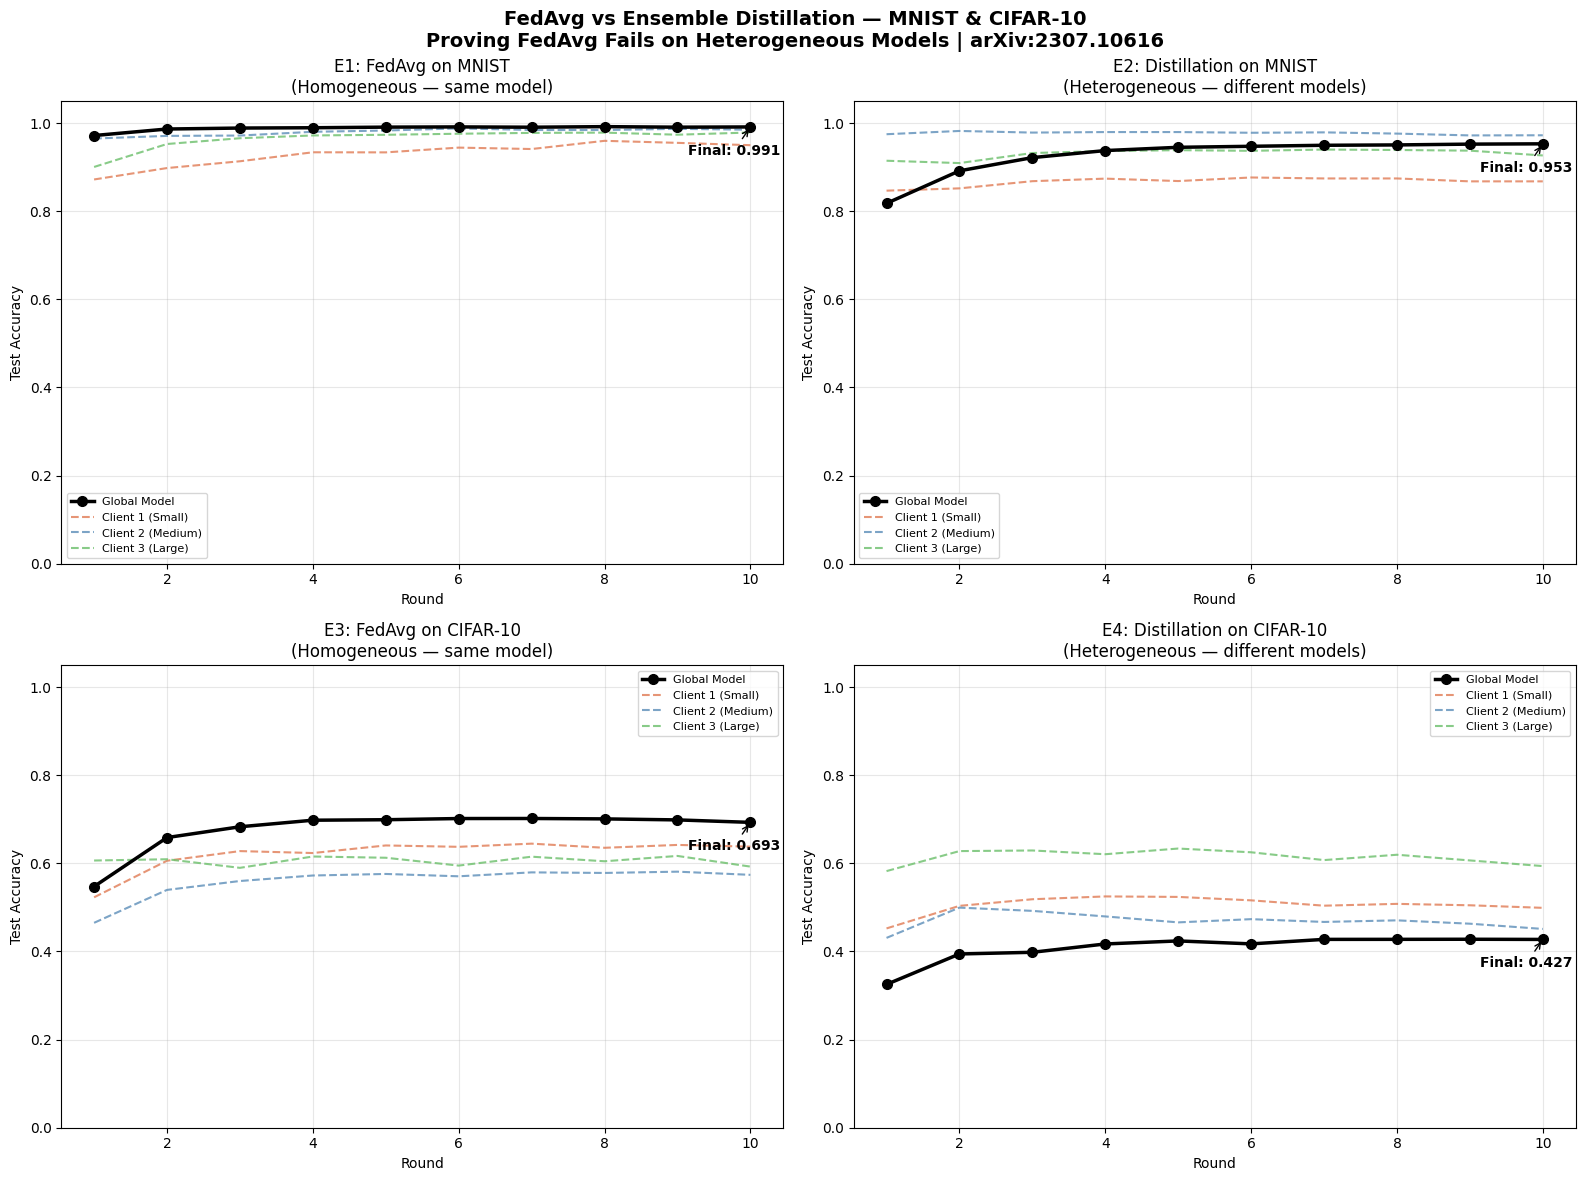

 Plot saved as hfl_proof_results.png


In [ ]:
rounds = list(range(1, CONFIG['num_rounds']+1))
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(
    'FedAvg vs Ensemble Distillation — MNIST & CIFAR-10\n'
    'Proving FedAvg Fails on Heterogeneous Models | arXiv:2307.10616',
    fontsize=14, fontweight='bold'
)

colors = ['#e07b54','#5b8db8','#6bbf6a']
cnames = ['Client 1 (Small)', 'Client 2 (Medium)', 'Client 3 (Large)']

for ax, hist, title in zip(
    axes.flat,
    [e1, e2, e3, e4],
    [
        'E1: FedAvg on MNIST\n(Homogeneous — same model)',
        'E2: Distillation on MNIST\n(Heterogeneous — different models)',
        'E3: FedAvg on CIFAR-10\n(Homogeneous — same model)',
        'E4: Distillation on CIFAR-10\n(Heterogeneous — different models)',
    ]
):
    ax.plot(rounds, hist['global_acc'], 'k-o', lw=2.5, ms=7, label='Global Model', zorder=5)
    for i, (name, color) in enumerate(zip(cnames, colors)):
        ax.plot(rounds, [r[i] for r in hist['client_accs']], '--',
                lw=1.5, ms=4, color=color, label=name, alpha=0.8)
    ax.set(xlabel='Round', ylabel='Test Accuracy', title=title)
    ax.legend(fontsize=8); ax.grid(alpha=0.3); ax.set_ylim(0, 1.05)
    final = hist['global_acc'][-1]
    ax.annotate(f'Final: {final:.3f}', xy=(CONFIG['num_rounds'], final),
                xytext=(-45, -20), textcoords='offset points',
                fontsize=10, fontweight='bold',
                arrowprops=dict(arrowstyle='->', color='black'))

plt.tight_layout()
plt.savefig('hfl_proof_results.png', dpi=150, bbox_inches='tight')
plt.show()
print(' Plot saved as hfl_proof_results.png')

---
## Section 9: Final Comparison Table

In [ ]:
print('='*70)
print('  COMPLETE RESULTS — FedAvg vs Distillation on MNIST & CIFAR-10')
print('='*70)
print(f'  {"":<30} {"E1 FedAvg":>10} {"E2 Distill":>12} {"E3 FedAvg":>10} {"E4 Distill":>12}')
print(f'  {"":<30} {"MNIST":>10} {"MNIST":>12} {"CIFAR-10":>10} {"CIFAR-10":>12}')
print(f'  {"-"*66}')
print(f'  {"Global Model Accuracy":<30} {e1["global_acc"][-1]:>10.4f} {e2["global_acc"][-1]:>12.4f} {e3["global_acc"][-1]:>10.4f} {e4["global_acc"][-1]:>12.4f}')
print(f'  {"Client 1 (Small CNN)":<30} {e1["client_accs"][-1][0]:>10.4f} {e2["client_accs"][-1][0]:>12.4f} {e3["client_accs"][-1][0]:>10.4f} {e4["client_accs"][-1][0]:>12.4f}')
print(f'  {"Client 2 (Medium CNN)":<30} {e1["client_accs"][-1][1]:>10.4f} {e2["client_accs"][-1][1]:>12.4f} {e3["client_accs"][-1][1]:>10.4f} {e4["client_accs"][-1][1]:>12.4f}')
print(f'  {"Client 3 (Large CNN)":<30} {e1["client_accs"][-1][2]:>10.4f} {e2["client_accs"][-1][2]:>12.4f} {e3["client_accs"][-1][2]:>10.4f} {e4["client_accs"][-1][2]:>12.4f}')
print(f'  {"-"*66}')
print(f'  {"Supports asymmetric models?":<30} {" No":>10} {" Yes":>12} {" No":>10} {" Yes":>12}')
print(f'  {"Crashes if models differ?":<30} {" Yes":>10} {" No":>12} {" Yes":>10} {" No":>12}')
print(f'  {"Shares raw data?":<30} {"No":>10} {"No":>12} {"No":>10} {"No":>12}')
print('='*70)
print()
print('KEY FINDING:')
print(f'  FedAvg on MNIST    : {e1["global_acc"][-1]:.4f} (works, but needs same model)')
print(f'  Distillation MNIST : {e2["global_acc"][-1]:.4f} (works with different models)')
print(f'  FedAvg on CIFAR-10 : {e3["global_acc"][-1]:.4f} (works, but needs same model)')
print(f'  Distillation CIFAR : {e4["global_acc"][-1]:.4f} (works with different models)')
print()
print('  Accuracy gap (MNIST)   :', f'{e1["global_acc"][-1] - e2["global_acc"][-1]:.4f}')
print('  Accuracy gap (CIFAR-10):', f'{e3["global_acc"][-1] - e4["global_acc"][-1]:.4f}')
print('  --> This gap is the COST of supporting real-world device heterogeneity.')

  COMPLETE RESULTS — FedAvg vs Distillation on MNIST & CIFAR-10
                                  E1 FedAvg   E2 Distill  E3 FedAvg   E4 Distill
                                      MNIST        MNIST   CIFAR-10     CIFAR-10
  ------------------------------------------------------------------
  Global Model Accuracy              0.9914       0.9531     0.6931       0.4274
  Client 1 (Small CNN)               0.9500       0.8679     0.6380       0.4991
  Client 2 (Medium CNN)              0.9851       0.9725     0.5740       0.4512
  Client 3 (Large CNN)               0.9788       0.9267     0.5927       0.5939
  ------------------------------------------------------------------
  Supports asymmetric models?            No          Yes         No          Yes
  Crashes if models differ?             Yes           No        Yes           No
  Shares raw data?                       No           No         No           No

KEY FINDING:
  FedAvg on MNIST    : 0.9914 (works, but needs same mo